# Análise Exploratória de Dados (EDA): Preço de Passagens Aéreas

**Projeto:** Data Science & Machine Learning Practice  
**Módulo:** 01 - Análise Exploratória de Dados (EDA)  
**Dataset:** Flight Price Prediction (`flight_price.xlsx`)  

---

## Objetivo Deste Notebook
O objetivo desta etapa é realizar uma **Análise Exploratória de Dados (EDA) completa, visual e estatística**, compreendendo:
- A distribuição e comportamento da variável alvo (`Price`).
- Fatores determinantes no preço de uma passagem aérea (companhia aérea, paradas, sazonalidade, duração).
- Padrões temporais (dias da semana, meses) preservando a linha do tempo.
- Detecção e análise de inconsistências e anomalias na base de dados.

---

## Abordagem Crítica vs. Aula Tradicional
Neste estudo, adotei uma postura crítica em relação à aula do curso:

| Aspecto | Abordagem da Aula (Professor) | Minha Abordagem (Boas Práticas de EDA) |
| :--- | :--- | :--- |
| **Foco da Etapa** | Fez apenas pré-processamento e encoding direto para o scikit-learn. | EDA aprofundada com estatística descritiva e visualizações analíticas. |
| **Coluna de Data (`Date_of_Journey`)** | Quebrou em dia/mês/ano inteiros e **deletou** a coluna original. | **Preservei a data como `datetime`**. Permite analisar séries temporais, gráficos contínuos e dia da semana. |
| **Horários de Chegada (`Arrival_Time`)** | Dropou datas associadas sem verificar voos que viram a noite. | Avaliei voos com chegada no dia seguinte e horários de partida e chegada. |
| **Tratamento de Nulos** | Imputou `Total_Stops` nulo cegamente com `1` via `.map()`. | Investiguei o caso (apenas 1 linha em 10.683) e tomei uma decisão estatisticamente fundamentada. |
| **Visualizações** | Importou `matplotlib` e `seaborn`, mas **não gerou nenhum gráfico**. | Criei gráficos exploratórios para cada hipótese de negócio levantada. |


## 1. Setup e Importação de Bibliotecas


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings

warnings.filterwarnings('ignore')

# Configurações estéticas padrão para os gráficos
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12


## 2. Carregamento dos Dados Brutos

Carregamento do arquivo a partir de `data/raw/flight_price.xlsx`. Criei uma lógica para localizar o arquivo tanto se o notebook for executado a partir da pasta raiz do projeto quanto de dentro da pasta `notebooks/01_eda/`.


In [2]:
# Localização flexível do arquivo
file_paths = [
    '../../data/raw/flight_price.xlsx',
    'data/raw/flight_price.xlsx',
    'flight_price.xlsx'
]

raw_path = None
for path in file_paths:
    if os.path.exists(path):
        raw_path = path
        break

if raw_path is None:
    raise FileNotFoundError("Arquivo 'flight_price.xlsx' não encontrado nos caminhos esperados.")

print(f"Carregando dados de: {raw_path}")
df_raw = pd.read_excel(raw_path)

# Cópia para preservar o dataframe bruto intacto
df = df_raw.copy()
print(f"Shape do Dataset: {df.shape[0]} linhas e {df.shape[1]} colunas.")


Carregando dados de: ../../data/raw/flight_price.xlsx
Shape do Dataset: 10683 linhas e 11 colunas.


## 3. Inspeção Inicial e Visão Geral da Estrutura

Inspeção das primeiras linhas, últimas linhas e do resumo estrutural com tipos e contagens de nulos.


In [3]:
df.head()


,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302


In [4]:
df.tail()


,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
10678,Air Asia,9/04/2019,Kolkata,Banglore,CCU → BLR,19:55,22:25,2h 30m,non-stop,No info,4107
10679,Air India,27/04/2019,Kolkata,Banglore,CCU → BLR,20:45,23:20,2h 35m,non-stop,No info,4145
10680,Jet Airways,27/04/2019,Banglore,Delhi,BLR → DEL,08:20,11:20,3h,non-stop,No info,7229
10681,Vistara,01/03/2019,Banglore,New Delhi,BLR → DEL,11:30,14:10,2h 40m,non-stop,No info,12648
10682,Air India,9/05/2019,Delhi,Cochin,DEL → GOI → BOM → COK,10:55,19:15,8h 20m,2 stops,No info,11753


In [5]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 10683 entries, 0 to 10682
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Airline          10683 non-null  str  
 1   Date_of_Journey  10683 non-null  str  
 2   Source           10683 non-null  str  
 3   Destination      10683 non-null  str  
 4   Route            10682 non-null  str  
 5   Dep_Time         10683 non-null  str  
 6   Arrival_Time     10683 non-null  str  
 7   Duration         10683 non-null  str  
 8   Total_Stops      10682 non-null  str  
 9   Additional_Info  10683 non-null  str  
 10  Price            10683 non-null  int64
dtypes: int64(1), str(10)
memory usage: 1.8 MB


In [ ]:
# Resumo estatístico inicial da única variável numérica original (Price)
df.describe().T


,Price,Journey_Date,Journey_Day,Journey_Month,Is_Weekend,Duration_Minutes
count,10462.000000,10462,10462.000000,10462.000000,10462.000000,10462.000000
mean,9026.790289,2019-05-04 13:38:33.056777,13.463200,4.701491,0.293634,629.781591
min,1759.000000,2019-03-01 00:00:00,1.000000,3.000000,0.000000,5.000000
25%,5224.000000,2019-03-27 00:00:00,6.000000,3.000000,0.000000,170.000000
50%,8266.000000,2019-05-15 00:00:00,12.000000,5.000000,0.000000,505.000000
75%,12344.750000,2019-06-06 00:00:00,21.000000,6.000000,1.000000,910.000000
max,79512.000000,2019-06-27 00:00:00,27.000000,6.000000,1.000000,2860.000000
std,4624.849541,NaN,8.467493,1.163802,0.455448,500.699045


## 4. Avaliação da Qualidade dos Dados

### 4.1 Valores Ausentes (Missing Values)


In [7]:
missing = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df)) * 100
missing_df = pd.DataFrame({'Total Nulos': missing, 'Percentual (%)': missing_pct})
missing_df[missing_df['Total Nulos'] > 0]


,Total Nulos,Percentual (%)
Route,1,0.009361
Total_Stops,1,0.009361


> ### Nota Crítica 1: O Tratamento do Valor Nulo em `Total_Stops`
>
> Na aula, o professor fez diretamente:
> ```python
> df['Total_Stops'] = df['Total_Stops'].map({'non-stop': 0, '1 stop': 1, '2 stops': 2, '3 stops': 3, '4 stops': 4, np.nan: 1})
> ```
> Ele imputou `1` simplesmente porque era a moda (`1 stop`), sem inspecionar a linha.
>
> Abaixo inspeciono esse registro específico:


In [8]:
# Inspecionando o único registro com Total_Stops nulo
df[df['Total_Stops'].isnull()]


,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
9039,Air India,6/05/2019,Delhi,Cochin,NaN,09:45,09:25 07 May,23h 40m,NaN,No info,7480


**Conclusão sobre a Nota Crítica 1:**  
Trata-se de apenas **1 linha** em um dataset de **10.683 registros** (apenas **0.009%** dos dados), e ela possui **tanto a rota (`Route`) quanto as paradas (`Total_Stops`) ausentes**.  
Em cenários de produção, tentar assumir arbitrariamente que um voo de Delhi para Cochin fez escala sem ter a rota gera ruído desnecessário. A decisão mais rigorosa e profissional é simplesmente remover essa linha isolada.


In [9]:
# Removendo o único registro com valor nulo
df.dropna(subset=['Total_Stops'], inplace=True)
print(f"Shape após remoção do nulo: {df.shape}")


Shape após remoção do nulo: (10682, 11)


### 4.2 Verificação de Linhas Duplicadas


In [10]:
duplicates_count = df.duplicated().sum()
print(f"Total de registros idênticos duplicados: {duplicates_count} ({duplicates_count / len(df) * 100:.2f}%)")


Total de registros idênticos duplicados: 220 (2.06%)


In [11]:
# Exemplo de duplicatas encontradas
df[df.duplicated(keep=False)].sort_values(by=['Date_of_Journey', 'Airline', 'Dep_Time']).head(6)


,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
6321,Air India,01/03/2019,Banglore,New Delhi,BLR → BOM → AMD → DEL,08:50,23:55 02 Mar,39h 5m,2 stops,No info,17135
9848,Air India,01/03/2019,Banglore,New Delhi,BLR → BOM → AMD → DEL,08:50,23:55 02 Mar,39h 5m,2 stops,No info,17135
572,Air India,03/03/2019,Banglore,New Delhi,BLR → DEL,21:10,23:55,2h 45m,non-stop,No info,7591
8168,Air India,03/03/2019,Banglore,New Delhi,BLR → DEL,21:10,23:55,2h 45m,non-stop,No info,7591
6196,IndiGo,03/03/2019,Banglore,New Delhi,BLR → DEL,08:30,11:30,3h,non-stop,No info,6860
10275,IndiGo,03/03/2019,Banglore,New Delhi,BLR → DEL,08:30,11:30,3h,non-stop,No info,6860


Existem mais de 200 linhas duplicadas. Em voos comerciais com mesmo dia, horário e companhia, passagens com valores idênticos podem ocorrer. No entanto, para manter a análise exploratória limpa e sem distorções de peso amostral, optei por remover essas duplicatas exatas.


In [12]:
# Removendo registros duplicados exatos
df.drop_duplicates(inplace=True)
print(f"Shape após remoção de duplicatas: {df.shape}")


Shape após remoção de duplicatas: (10462, 11)


## 5. Tratamento dos Dados para EDA (Sem Destruir a Linha do Tempo)

> ### Nota Crítica 2: A Preservação da Linha do Tempo
> 
> Na aula, o professor fez:
> ```python
> df['Date'] = df['Date_of_Journey'].str.split('/').str[0].astype(int)
> df['Month'] = df['Date_of_Journey'].str.split('/').str[1].astype(int)
> df['Year'] = df['Date_of_Journey'].str.split('/').str[2].astype(int)
> df.drop('Date_of_Journey', axis=1, inplace=True)
> ```
> 
> **Por que considero isso um erro na fase de EDA?**
> 1. Perde-se a variável temporal contínua (`datetime`), impossibilitando gráficos de linha e acompanhamento da série temporal.
> 2. Perde-se o contexto do calendário: dia da semana, sazonalidade e dias que antecedem finais de semana.
> 3. Tratar `Date` como inteiro (1 a 31) induz distorções em modelos lineares (como se o dia 30 fosse 30 vezes mais expressivo que o dia 1, quando na verdade dia 31 e dia 1 do mês seguinte são contíguos).
>
> **O que fiz aqui:**  
> Converti a data para um verdadeiro objeto `datetime` e extraí atributos analíticos enriquecidos sem descartar a linha do tempo.


In [13]:
# Conversão rigorosa para datetime
df['Journey_Date'] = pd.to_datetime(df['Date_of_Journey'], format='%d/%m/%Y')

# Extração de dimensões temporais analíticas
df['Journey_Day'] = df['Journey_Date'].dt.day
df['Journey_Month'] = df['Journey_Date'].dt.month
df['Journey_Month_Name'] = df['Journey_Date'].dt.strftime('%B')
df['Journey_Day_of_Week'] = df['Journey_Date'].dt.day_name()
df['Is_Weekend'] = df['Journey_Date'].dt.weekday.isin([5, 6]).astype(int)

df[['Date_of_Journey', 'Journey_Date', 'Journey_Month_Name', 'Journey_Day_of_Week', 'Is_Weekend']].head()


,Date_of_Journey,Journey_Date,Journey_Month_Name,Journey_Day_of_Week,Is_Weekend
0,24/03/2019,2019-03-24,March,Sunday,1
1,1/05/2019,2019-05-01,May,Wednesday,0
2,9/06/2019,2019-06-09,June,Sunday,1
3,12/05/2019,2019-05-12,May,Sunday,1
4,01/03/2019,2019-03-01,March,Friday,0


### 5.1 Padronização das Cidades de Destino e Informações Adicionais

> ### Nota Crítica 3: Inconsistências de Categoria
> Em `Destination` constam tanto `Delhi` quanto `New Delhi`. Ambas se referem à mesma cidade/área metropolitana na Índia.  
> Além disso, em `Additional_Info`, há `No info` e `No Info` (inconsistência apenas de maiúscula/minúscula).


In [14]:
print("Valores únicos antes da padronização:")
print("Destination:", df['Destination'].unique().tolist())
print("Additional_Info:", df['Additional_Info'].unique().tolist())


Valores únicos antes da padronização:
Destination: ['New Delhi', 'Banglore', 'Cochin', 'Kolkata', 'Delhi', 'Hyderabad']
Additional_Info: ['No info', 'In-flight meal not included', 'No check-in baggage included', '1 Short layover', 'No Info', '1 Long layover', 'Change airports', 'Business class', 'Red-eye flight', '2 Long layover']


In [15]:
# Padronização de Delhi e New Delhi
df['Destination'] = df['Destination'].replace('New Delhi', 'Delhi')

# Padronização de No info e No Info
df['Additional_Info'] = df['Additional_Info'].replace('No Info', 'No info')

print("\nValores únicos após a padronização:")
print("Destination:", df['Destination'].unique().tolist())
print("Additional_Info:", df['Additional_Info'].unique().tolist())



Valores únicos após a padronização:
Destination: ['Delhi', 'Banglore', 'Cochin', 'Kolkata', 'Hyderabad']
Additional_Info: ['No info', 'In-flight meal not included', 'No check-in baggage included', '1 Short layover', '1 Long layover', 'Change airports', 'Business class', 'Red-eye flight', '2 Long layover']


### 5.2 Tratamento da Duração do Voo em Minutos

A coluna `Duration` original é composta por texto (ex: `'2h 50m'`, `'19h'`, `'45m'`). Para analisar a correlação contínua com o preço e plotar gráficos de dispersão, criei a variável numérica `Duration_Minutes`.


In [16]:
def duration_to_minutes(duration_str):
    hours = 0
    minutes = 0
    parts = duration_str.split(' ')
    for p in parts:
        if 'h' in p:
            hours = int(p.replace('h', ''))
        elif 'm' in p:
            minutes = int(p.replace('m', ''))
    return hours * 60 + minutes

df['Duration_Minutes'] = df['Duration'].apply(duration_to_minutes)
df[['Duration', 'Duration_Minutes']].head()


,Duration,Duration_Minutes
0,2h 50m,170
1,7h 25m,445
2,19h,1140
3,5h 25m,325
4,4h 45m,285


## 6. Análise Univariada

Nesta etapa, analiso cada variável individualmente para compreender sua distribuição, dispersão e assimetrias.

### 6.1 Análise da Variável Alvo (`Price`)


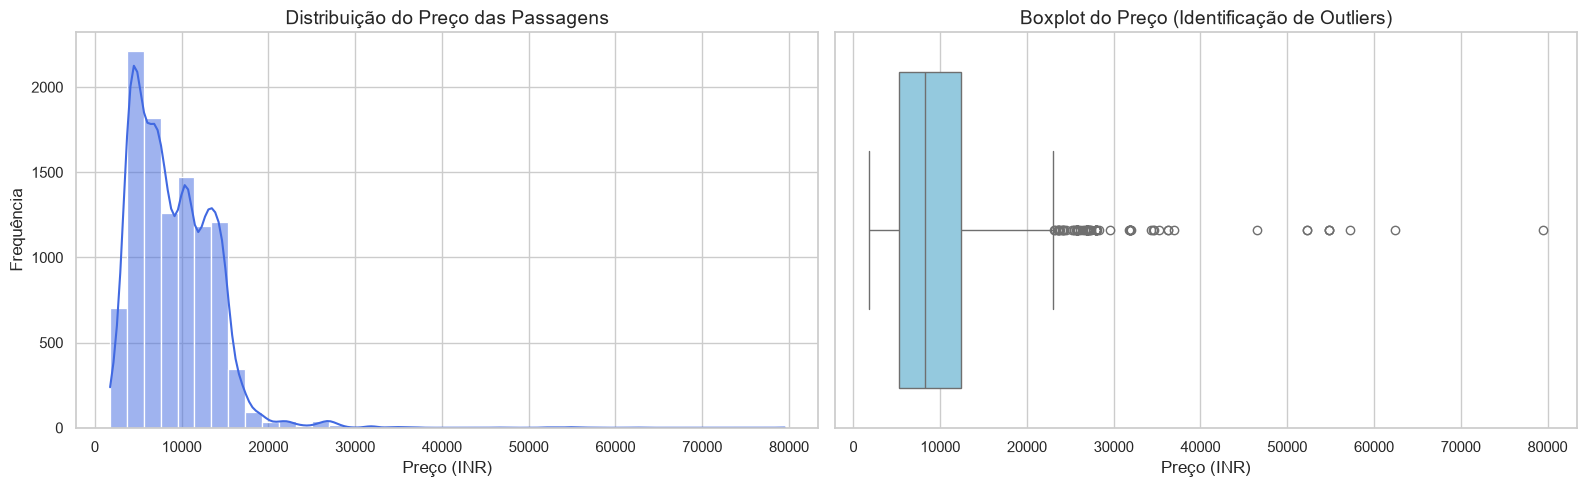

Média: INR 9,026.79
Mediana: INR 8,266.00
Desvio Padrão: INR 4,624.85
Assimetria (Skewness): 1.86 (Valores > 1 indicam forte cauda longa à direita)
Curtose: 13.53


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Histograma com KDE
sns.histplot(df['Price'], kde=True, color='royalblue', bins=40, ax=axes[0])
axes[0].set_title("Distribuição do Preço das Passagens")
axes[0].set_xlabel("Preço (INR)")
axes[0].set_ylabel("Frequência")

# Boxplot
sns.boxplot(x=df['Price'], color='skyblue', ax=axes[1])
axes[1].set_title("Boxplot do Preço (Identificação de Outliers)")
axes[1].set_xlabel("Preço (INR)")

plt.tight_layout()
plt.show()

# Estatísticas descritivas completas
mean_price = df['Price'].mean()
median_price = df['Price'].median()
std_price = df['Price'].std()
skew_price = df['Price'].skew()
kurt_price = df['Price'].kurt()

print(f"Média: INR {mean_price:,.2f}")
print(f"Mediana: INR {median_price:,.2f}")
print(f"Desvio Padrão: INR {std_price:,.2f}")
print(f"Assimetria (Skewness): {skew_price:.2f} (Valores > 1 indicam forte cauda longa à direita)")
print(f"Curtose: {kurt_price:.2f}")


### 6.2 Análise dos Outliers de Preço (Identificação pelo Método IQR)

O boxplot acima evidencia uma cauda longa à direita com passagens ultrapassando INR 40.000 e até INR 70.000.  
Abaixo investigo a composição desses valores extremos.


In [18]:
Q1 = df['Price'].quantile(0.25)
Q3 = df['Price'].quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR

outliers_price = df[df['Price'] > upper_bound]
print(f"Limite Superior (IQR 1.5): INR {upper_bound:,.2f}")
print(f"Total de registros considerados outliers: {len(outliers_price)} ({len(outliers_price)/len(df)*100:.2f}%)")

# Companhias aéreas com maior número de outliers
outliers_price['Airline'].value_counts()


Limite Superior (IQR 1.5): INR 23,025.88
Total de registros considerados outliers: 94 (0.90%)


Airline
Jet Airways             62
Air India               15
Multiple carriers       10
Jet Airways Business     6
SpiceJet                 1
Name: count, dtype: int64

In [19]:
# Inspecionando os voos mais caros do dataset (> INR 50.000)
df[df['Price'] > 50000][['Airline', 'Date_of_Journey', 'Source', 'Destination', 'Total_Stops', 'Additional_Info', 'Price']]


,Airline,Date_of_Journey,Source,Destination,Total_Stops,Additional_Info,Price
657,Jet Airways Business,01/03/2019,Banglore,Delhi,1 stop,No info,52229
1478,Jet Airways,18/03/2019,Banglore,Delhi,1 stop,No info,54826
2618,Jet Airways,18/03/2019,Banglore,Delhi,1 stop,No info,54826
2924,Jet Airways Business,01/03/2019,Banglore,Delhi,1 stop,Business class,79512
5372,Jet Airways Business,01/03/2019,Banglore,Delhi,1 stop,Business class,62427
5439,Jet Airways,01/03/2019,Banglore,Delhi,1 stop,No info,54826
9715,Jet Airways Business,6/03/2019,Delhi,Cochin,2 stops,No info,52285
10364,Jet Airways Business,01/03/2019,Banglore,Delhi,1 stop,Business class,57209


**Insight da Análise de Outliers:**  
Ao inspecionar os voos com preços extremos (> INR 50.000), observo que todos estão vinculados à **Jet Airways**:
- **5 voos** estão categorizados explicitamente como **Jet Airways Business** (classe executiva, com passagens atingindo até INR 79.512).
- **3 voos** aparecem registrados sob a classe convencional da **Jet Airways** (todos com tarifa idêntica de INR 54.826 na rota Banglore -> Delhi durante o mês de março de 2019).

Isso evidencia que esses valores atípicos não pertencem unicamente à classe executiva rotulada, mas sim a uma dinâmica de tarifas muito elevadas da Jet Airways na rota Banglore -> Delhi em março de 2019 (período que coincidiu com a crise financeira e redução de oferta da companhia antes da suspensão de seus voos em abril/2019). Não se tratam de erros grosseiros de digitação, mas sim de comportamentos reais de preço que exigirão atenção e estratégias adequadas (como transformações logarítmicas ou tratamento de outliers) na fase de modelagem.


### 6.3 Frequência das Variáveis Categóricas


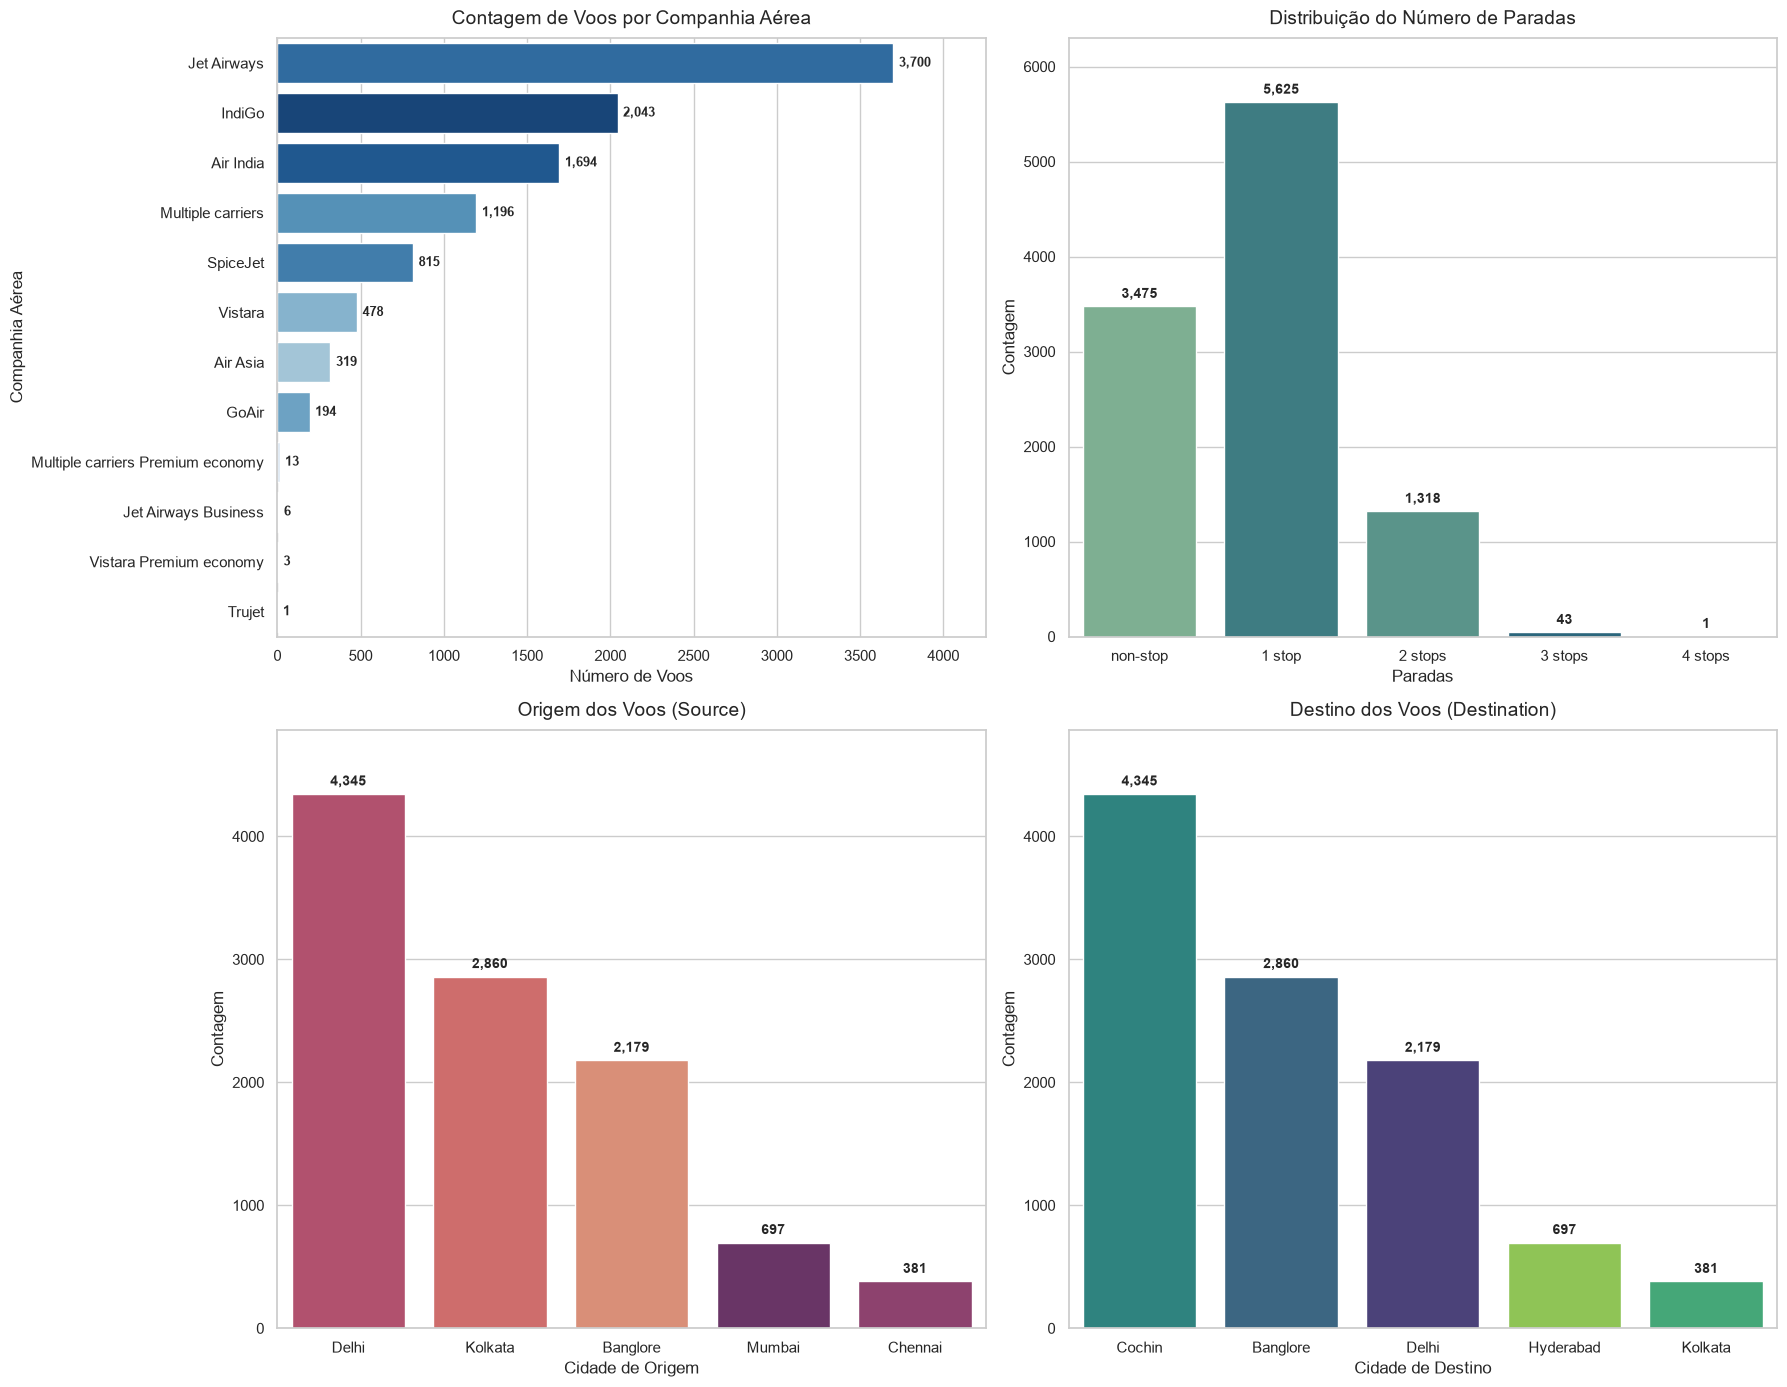

In [63]:
fig, axes = plt.subplots(2, 2, figsize=(18, 14))

# 1. Companhias Aereas (Barras horizontais)
order_airline = df['Airline'].value_counts().index
sns.countplot(data=df, y='Airline', order=order_airline, hue='Airline', palette='Blues_r', legend=False, ax=axes[0, 0])
axes[0, 0].set_title("Contagem de Voos por Companhia Aérea", fontsize=14, pad=10)
axes[0, 0].set_xlabel("Número de Voos")
axes[0, 0].set_ylabel("Companhia Aérea")
for c in axes[0, 0].containers:
    axes[0, 0].bar_label(c, fmt='{:,.0f}', padding=4, fontsize=9, fontweight='bold')
axes[0, 0].set_xlim(0, df['Airline'].value_counts().max() * 1.15)

# 2. Total de Paradas (Barras verticais)
order_stops = ['non-stop', '1 stop', '2 stops', '3 stops', '4 stops']
order_stops = [s for s in order_stops if s in df['Total_Stops'].unique()]
sns.countplot(data=df, x='Total_Stops', order=order_stops, hue='Total_Stops', palette='crest', legend=False, ax=axes[0, 1])
axes[0, 1].set_title("Distribuição do Número de Paradas", fontsize=14, pad=10)
axes[0, 1].set_xlabel("Paradas")
axes[0, 1].set_ylabel("Contagem")
for c in axes[0, 1].containers:
    axes[0, 1].bar_label(c, fmt='{:,.0f}', padding=4, fontsize=10, fontweight='bold')
axes[0, 1].set_ylim(0, df['Total_Stops'].value_counts().max() * 1.12)

# 3. Cidades de Origem (Barras verticais)
order_source = df['Source'].value_counts().index
sns.countplot(data=df, x='Source', order=order_source, hue='Source', palette='flare', legend=False, ax=axes[1, 0])
axes[1, 0].set_title("Origem dos Voos (Source)", fontsize=14, pad=10)
axes[1, 0].set_xlabel("Cidade de Origem")
axes[1, 0].set_ylabel("Contagem")
for c in axes[1, 0].containers:
    axes[1, 0].bar_label(c, fmt='{:,.0f}', padding=4, fontsize=10, fontweight='bold')
axes[1, 0].set_ylim(0, df['Source'].value_counts().max() * 1.12)

# 4. Cidades de Destino (Barras verticais)
order_dest = df['Destination'].value_counts().index
sns.countplot(data=df, x='Destination', order=order_dest, hue='Destination', palette='viridis', legend=False, ax=axes[1, 1])
axes[1, 1].set_title("Destino dos Voos (Destination)", fontsize=14, pad=10)
axes[1, 1].set_xlabel("Cidade de Destino")
axes[1, 1].set_ylabel("Contagem")
for c in axes[1, 1].containers:
    axes[1, 1].bar_label(c, fmt='{:,.0f}', padding=4, fontsize=10, fontweight='bold')
axes[1, 1].set_ylim(0, df['Destination'].value_counts().max() * 1.12)

plt.tight_layout()
plt.show()


## 7. Análise Bivariada e Multivariada (Cruzamento de Hipóteses)

Nesta seção, investigo as principais perguntas de negócio:
1. Qual companhia aérea pratica as passagens mais caras e mais econômicas?
2. Voos com escalas são mais caros ou mais baratos em relação a voos diretos?
3. Como o preço se comporta ao longo dos meses e dos dias da semana?
4. A duração total do voo possui correlação direta com o valor final?

---

### 7.1 Preço vs. Companhia Aérea


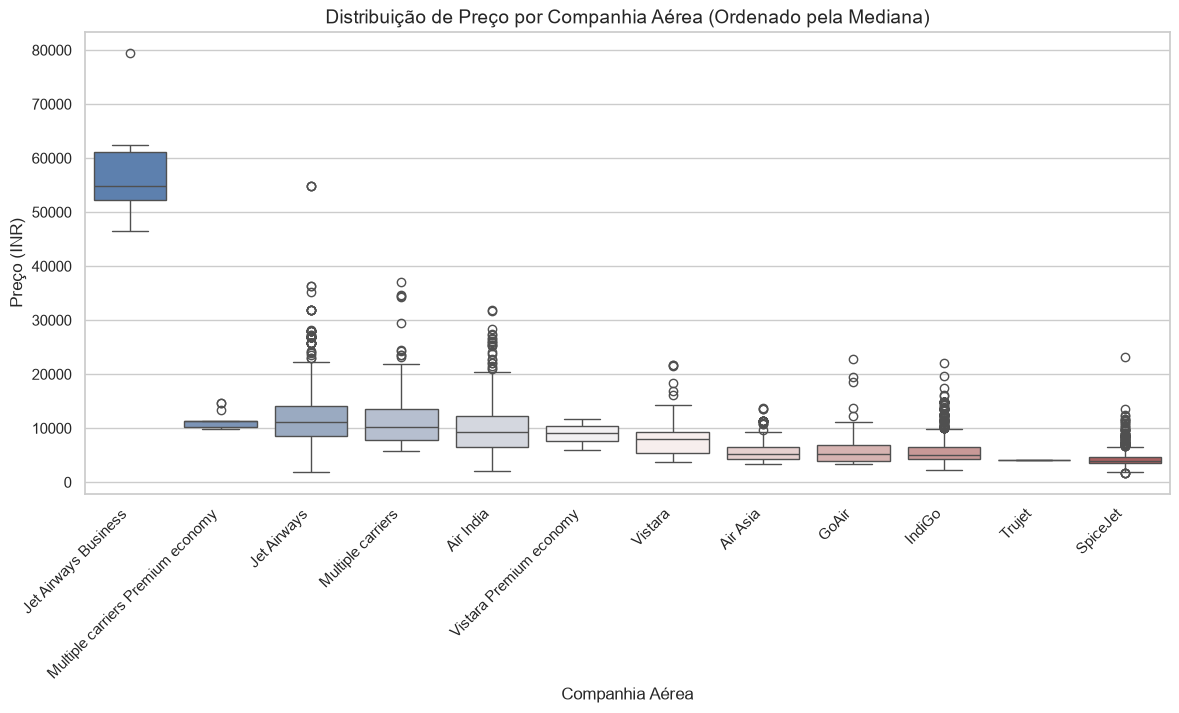

In [21]:
plt.figure(figsize=(14, 6))
airline_order = df.groupby('Airline')['Price'].median().sort_values(ascending=False).index

sns.boxplot(data=df, x='Airline', y='Price', order=airline_order, palette='vlag')
plt.title("Distribuição de Preço por Companhia Aérea (Ordenado pela Mediana)")
plt.xlabel("Companhia Aérea")
plt.ylabel("Preço (INR)")
plt.xticks(rotation=45, ha='right')
plt.show()


**Insights sobre Companhias Aéreas:**
- **Segmento de Luxo / Executiva:** A **Jet Airways Business** opera em um patamar de preços completamente isolado e descolado do restante do mercado, com mediana próxima de INR 54.700 e passagens que chegam a quase INR 80.000.
- **Faixa Superior Convencional (> INR 10.000):** Apenas **Jet Airways**, **Multiple carriers Premium economy** e **Multiple carriers** possuem medianas superiores a INR 10.000. Logo abaixo dessa faixa, a **Air India**, situando-se relativamente próxima desse grupo e completando o bloco de companhias tradicionais de grande porte.
- **Faixa Econômica (Low-Cost Consolidadas):** Olhando para as companhias efetivamente acessíveis e com volume representativo de voos, destacam-se **GoAir**, **Air Asia**, **IndiGo**, com mais de 2.000 voos) e **SpiceJet**. Essas quatro formam o verdadeiro bloco econômico do mercado indiano.
- **Atenção à Representatividade Amostral (Trujet e Categorias Raras):** A **Trujet** possui apenas **1 único registro** em todo o dataset, o que inviabiliza considerá-la estatisticamente representativa como companhia de mercado (podendo inclusive ser descartada na etapa de modelagem para evitar categorias unitárias). Cenário similar ocorre com **Vistara Premium economy** (apenas 3 voos) e **Multiple carriers Premium economy** (13 voos), cujas amostras são extremamente reduzidas frente ao volume total.


### 7.2 Preço vs. Número de Paradas (`Total_Stops`)


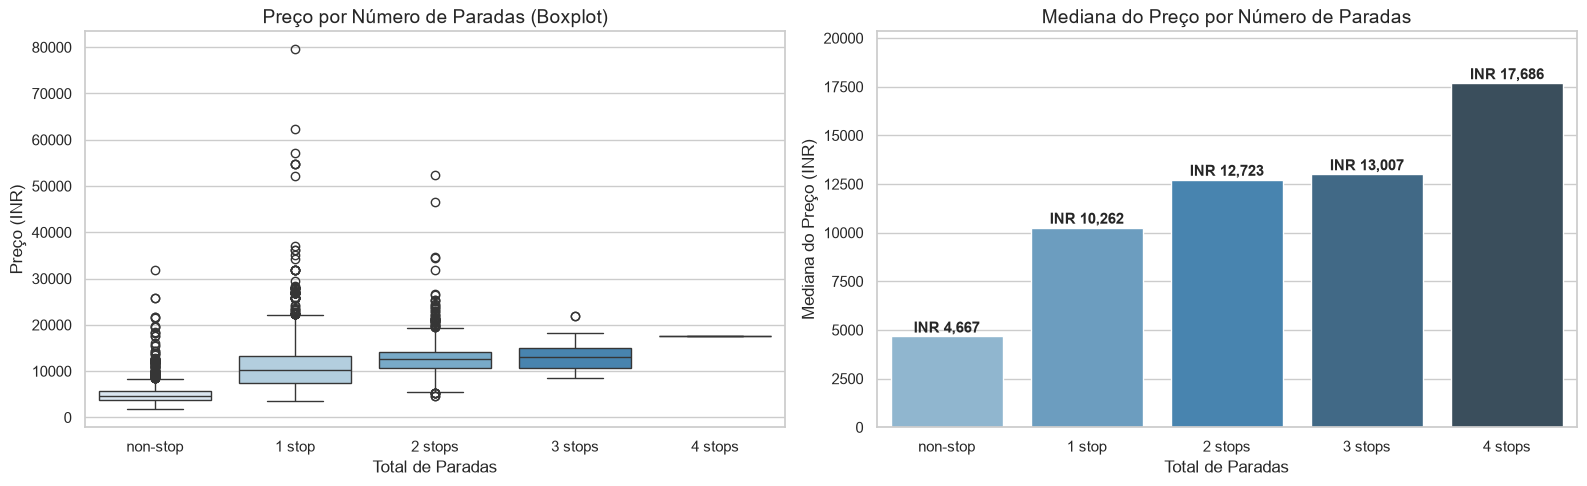

,mean,median,count
Total_Stops,,,
non-stop,5018.506763,4667.0,3475
1 stop,10594.123556,10262.0,5625
2 stops,12761.099393,12723.0,1318
3 stops,13260.674419,13007.0,43
4 stops,17686.000000,17686.0,1


In [65]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
# Boxplot por Paradas
sns.boxplot(data=df, x='Total_Stops', y='Price', order=order_stops, palette='Blues', ax=axes[0])
axes[0].set_title("Preço por Número de Paradas (Boxplot)")
axes[0].set_xlabel("Total de Paradas")
axes[0].set_ylabel("Preço (INR)")
# Mediana por Paradas
stops_summary = df.groupby('Total_Stops')['Price'].agg(['mean', 'median', 'count']).reindex(order_stops)
sns.barplot(x=stops_summary.index, y=stops_summary['median'], palette='Blues_d', ax=axes[1])
axes[1].set_title("Mediana do Preço por Número de Paradas")
axes[1].set_xlabel("Total de Paradas")
axes[1].set_ylabel("Mediana do Preço (INR)")
for i, val in enumerate(stops_summary['median']):
    axes[1].text(i, val + 200, f"INR {val:,.0f}", ha='center', fontweight='bold')
axes[1].set_ylim(0, stops_summary['median'].max() * 1.15)
plt.tight_layout()
plt.show()
stops_summary


**Insights sobre o Número de Paradas:**
- **Voos Diretos (Non-Stop) vs. Com Conexão:** Voos sem paradas possuem a menor mediana de preço. Em contrapartida, **todas as categorias com escalas (1, 2, 3 ou 4 paradas) apresentam medianas que superam os INR 10.000**, demonstrando um salto imediato de patamar tarifário:
  - Non-stop: ~INR 4.667
  - 1 parada: ~INR 10.262
  - 2 paradas: ~INR 12.723
  - 3 paradas: ~INR 13.007
  - 4 paradas: INR 17.686
- **A Relação entre Paradas, Distância e Duração:** À primeira vista, pode soar contraintuitivo que voos diretos sejam mais baratos, mas isso ocorre porque voos sem escalas costumam cobrir rotas mais curtas entre grandes capitais com alta concorrência de empresas low-cost. Conforme a distância e o tempo total de viagem aumentam para cruzar regiões mais distantes, o número de escalas necessárias sobe junto com os custos operacionais, elevando a tarifa final.
- **Representatividade Amostral (3 e 4 Paradas):**
  - **3 paradas:** Possui 43 voos (na base limpa).
  - **4 paradas:** Trata-se de **apenas 1 voo** no dataset inteiro.


### 7.3 Análise Temporal: Tendências e Padrões de Calendário

> A preservação do tipo `datetime` permite avaliar a série temporal contínua e a dinâmica dos dias da semana.


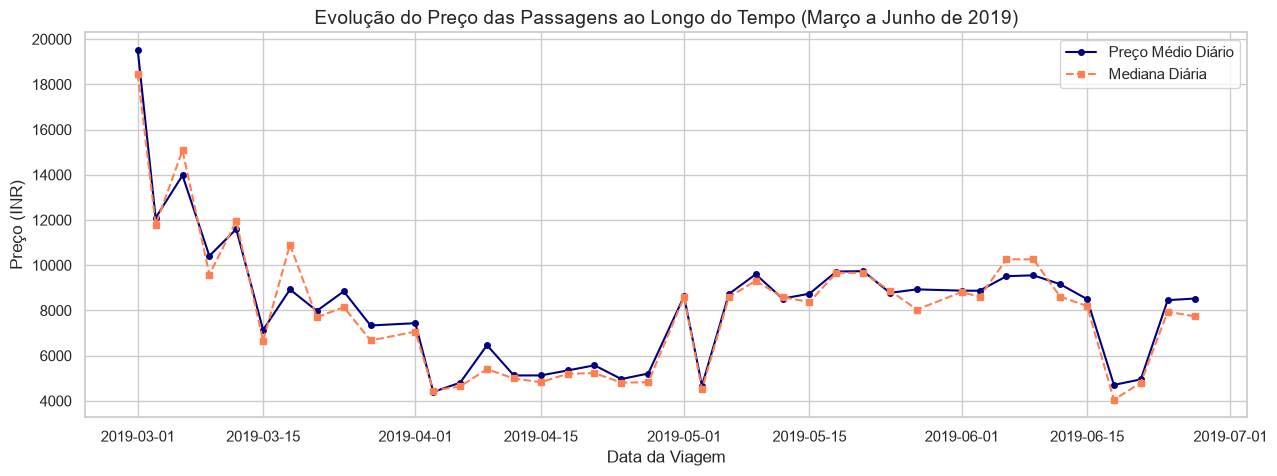

In [23]:
# 1. Evolução do Preço Médio Diário ao Longo do Tempo
daily_price = df.groupby('Journey_Date')['Price'].agg(['mean', 'median', 'count']).reset_index()

plt.figure(figsize=(15, 5))
plt.plot(daily_price['Journey_Date'], daily_price['mean'], marker='o', markersize=4, label='Preço Médio Diário', color='navy')
plt.plot(daily_price['Journey_Date'], daily_price['median'], marker='s', markersize=4, label='Mediana Diária', color='coral', linestyle='--')
plt.title("Evolução do Preço das Passagens ao Longo do Tempo (Março a Junho de 2019)")
plt.xlabel("Data da Viagem")
plt.ylabel("Preço (INR)")
plt.legend()
plt.show()


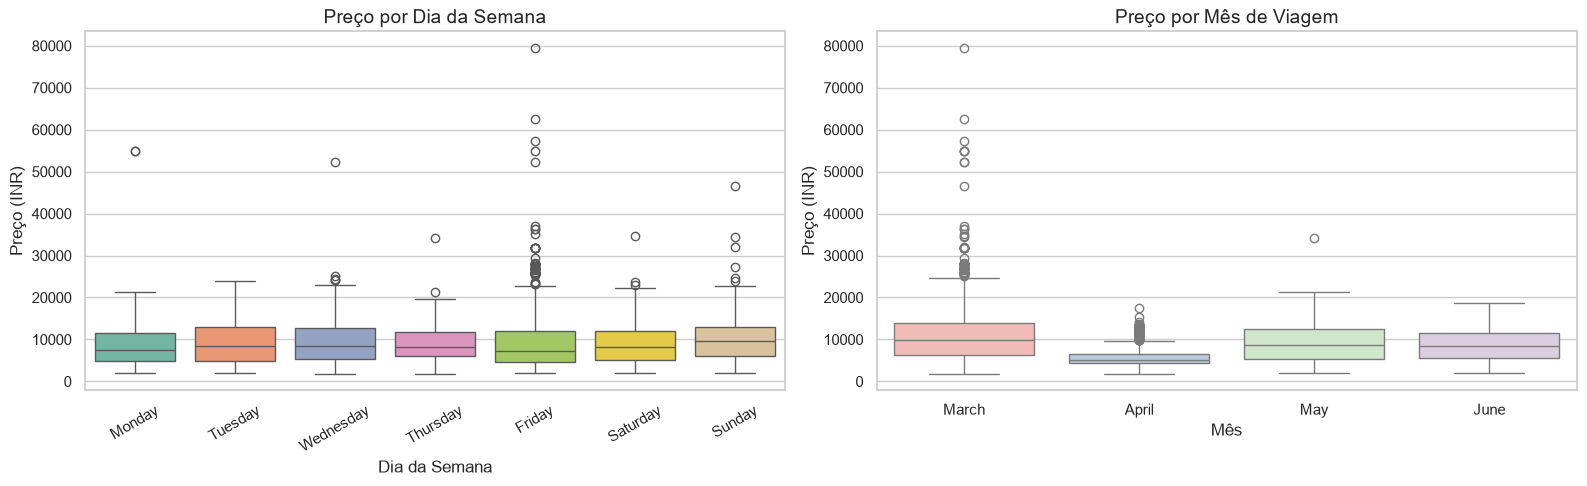

In [24]:
# 2. Variação de Preço por Dia da Semana e por Mês
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Preço por Dia da Semana
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
sns.boxplot(data=df, x='Journey_Day_of_Week', y='Price', order=days_order, palette='Set2', ax=axes[0])
axes[0].set_title("Preço por Dia da Semana")
axes[0].set_xlabel("Dia da Semana")
axes[0].set_ylabel("Preço (INR)")
axes[0].tick_params(axis='x', rotation=30)

# Preço por Mês
month_order = ['March', 'April', 'May', 'June']
month_order = [m for m in month_order if m in df['Journey_Month_Name'].unique()]
sns.boxplot(data=df, x='Journey_Month_Name', y='Price', order=month_order, palette='Pastel1', ax=axes[1])
axes[1].set_title("Preço por Mês de Viagem")
axes[1].set_xlabel("Mês")
axes[1].set_ylabel("Preço (INR)")

plt.tight_layout()
plt.show()


**Insights Temporais:**
- **Janela Amostral dos Dados (4 Meses):** Toda a base de dados original compreende voos realizados exclusivamente entre **1º de março de 2019 e 27 de junho de 2019** (não existem registros para os demais meses do ano no dataset original). Portanto, os quatro meses plotados representam 100% da série temporal disponível.
- **Comportamento Mensal:** O mês de **março** apresenta a maior mediana e a maior dispersão de preços, concentrando a grande maioria dos voos acima de INR 30.000 (período de fechamento de ano fiscal indiano e crise da Jet Airways). Em contrapartida, **abril** registra as tarifas mais baixas e menor dispersão do período analisado.
- **Padrão dos Dias da Semana:**
  - **Terça-feira (Sem Outliers):** É o **único dia da semana sem nenhum outlier registrado**. Não houve voos com discrepâncias absurdas ou valores descontrolados, exibindo uma curva tarifária altamente previsível.
  - **Quinta-feira (Menor Dispersão Central):** Apresenta o **menor intervalo interquartil** de toda a semana (a caixa do boxplot mais compacta), indicando que metade dos voos se concentra em uma faixa de preço muito estreita e com apenas dois outliers pontuais. É um dos dias mais estáveis para voar.
  - **Sexta-feira (Pico de Outliers):** É com folga o dia com **maior concentração de outliers (76 voos extremos)** e onde ocorreu o voo mais caro do dataset, refletindo compras corporativas de última hora e o encarecimento de passagens para o final de semana.
  - **Domingo (Maior Mediana):** Apresenta a **maior mediana de preço da semana**, podendo ser impulsionada pelo pico de demanda no retorno das viagens de fim de semana.


### 7.4 Preço vs. Duração do Voo


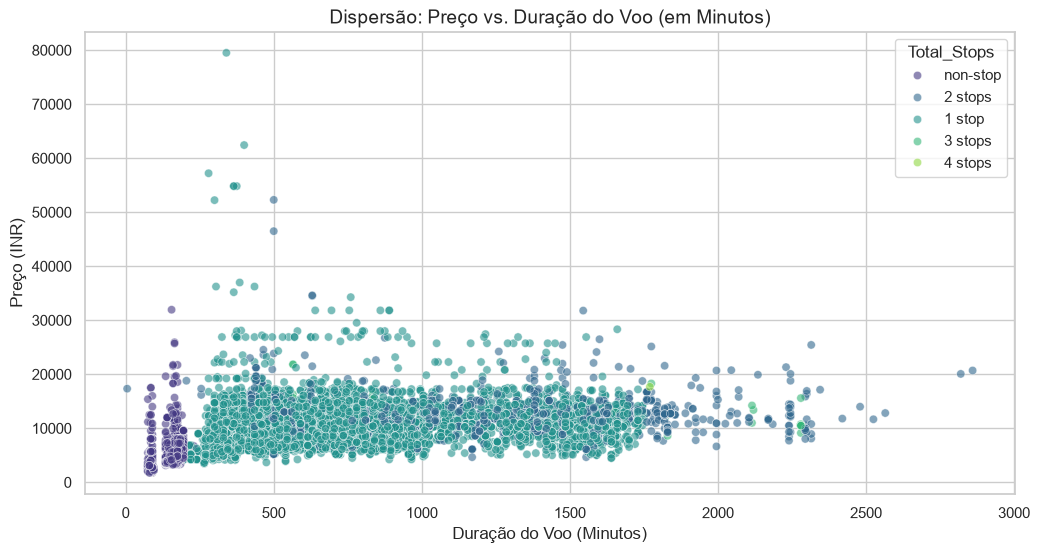

Correlação de Pearson (linear): 0.502
Correlação de Spearman (monótona): 0.694


In [25]:
plt.figure(figsize=(12, 6))
sns.scatterplot(
    data=df,
    x='Duration_Minutes',
    y='Price',
    hue='Total_Stops',
    alpha=0.6,
    palette='viridis'
)
plt.title("Dispersão: Preço vs. Duração do Voo (em Minutos)")
plt.xlabel("Duração do Voo (Minutos)")
plt.ylabel("Preço (INR)")
plt.show()

# Correlações lineares e monótonas
corr_pearson = df['Duration_Minutes'].corr(df['Price'], method='pearson')
corr_spearman = df['Duration_Minutes'].corr(df['Price'], method='spearman')
print(f"Correlação de Pearson (linear): {corr_pearson:.3f}")
print(f"Correlação de Spearman (monótona): {corr_spearman:.3f}")


### 7.5 Matriz de Preço Médio por Origem e Destino


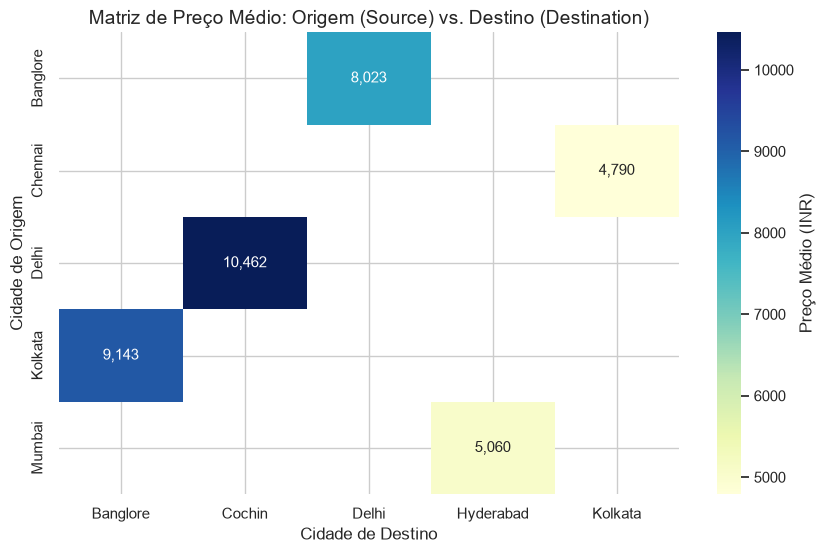

In [26]:
route_matrix = df.pivot_table(index='Source', columns='Destination', values='Price', aggfunc='mean')

plt.figure(figsize=(10, 6))
sns.heatmap(route_matrix, annot=True, fmt=',.0f', cmap='YlGnBu', cbar_kws={'label': 'Preço Médio (INR)'})
plt.title("Matriz de Preço Médio: Origem (Source) vs. Destino (Destination)")
plt.xlabel("Cidade de Destino")
plt.ylabel("Cidade de Origem")
plt.show()


## 8. Resumo dos Insights e Conclusões da EDA
A partir desta exploração fundamentada, destaco as seguintes conclusões:
1. **Assimetria Acentuada na Variável Alvo:**
   - O preço apresenta forte assimetria positiva à direita, influenciado por tarifas atípicas e passagens de classe executiva da *Jet Airways* e *Jet Airways Business* em março de 2019. Na etapa de modelagem, avaliarei a aplicação de transformações logarítmicas (como `np.log1p(Price)`) para estabilizar a variância residual.
2. **Impacto Decisivo do Número de Paradas e Distância:**
   - Voos diretos (non-stop) concentram as menores tarifas (~INR 4.667), enquanto qualquer voo com conexões (1 a 4 paradas) supera a marca de INR 10.000 em suas medianas, refletindo trajetos de maior distância, maior tempo de voo e conexões entre regiões distantes.
3. **Diferenciação por Companhia Aérea e Representatividade:**
   - *SpiceJet*, *IndiGo*, *GoAir* e *Air Asia* formam o bloco econômico com medianas entre INR 3.800 e 5.200. No segmento superior convencional, *Jet Airways*, *Multiple carriers* e *Air India* gravitam na faixa de INR 9.400 a 11.500, enquanto a *Jet Airways Business* isola-se acima de INR 54.000. Companhias ou categorias raras (como *Trujet*, com apenas 1 voo) deverão ser tratadas com cautela na modelagem.
4. **Relevância do Fator Temporal e Padrão Semanal:**
   - A base é limitada a 4 meses (março a junho de 2019). Março registrou as tarifas mais elevadas e maior volatilidade. No padrão semanal, a terça-feira se destaca por não possuir nenhum outlier, a quinta-feira pela menor dispersão central (menor IQR), a sexta-feira pela forte concentração de outliers extremos e o domingo pela maior mediana de preços.
5. **Diretrizes para o Próximo Módulo (`02_feature_engineering/`):**
   - Criação de atributos derivados de horário (período do dia da partida: madrugada, manhã, tarde, noite).
   - Codificação de atributos ordinais (`Total_Stops`) e nominais (`Airline`, `Source`, `Destination`).
   - Avaliação crítica entre One-Hot Encoding e abordagens ordinais/alvo para evitar explosão dimensional.
   - Exportação da base estruturada para a pasta `data/processed/`.


## 9. Exportação da Base Pré-Tratada para `data/processed/`


In [27]:
# Diretório de destino
output_dir = '../../data/processed' if os.path.exists('../../data/processed') else 'data/processed'
output_path = os.path.join(output_dir, 'flight_price_cleaned.csv')

# Salvamento da base tratada para consumo do próximo notebook
df.to_csv(output_path, index=False)
print(f"Base tratada salva com sucesso em: {output_path} ({df.shape[0]} linhas, {df.shape[1]} colunas)")


Base tratada salva com sucesso em: ../../data/processed\flight_price_cleaned.csv (10462 linhas, 18 colunas)
